<div style="background:linear-gradient(120deg,#EDE7FF 0%,#E3F0FF 55%,#E6FBF7 100%); color:#2A1B5C; padding:22px 26px; border-radius:14px; border:1px solid #DCD3FF; margin-bottom:8px;">

<h1 style="margin:0 0 6px 0; color:#3B1F7A">07 · Classical NLP: Bag-of-Words, TF-IDF and text classifiers</h1>

<p style="margin:0 0 10px 0; font-size:1.1em; color:#4C3A8C">Level 2: detecting side-effect sentences with interpretable baselines that later models must beat</p>

| | |
|---|---|
| **Task** | Does a sentence describe an **adverse drug event (ADE)**? Binary classification on ADE Corpus v2 (medical case reports) |
| **Why it matters** | Reps must report side effects mentioned by doctors. The product flags them in visit notes (🔴 in the brief) |
| **Code** | `src/glp1_intel/nlp/classical.py` |
| **Output** | metrics in `reports/evaluation/nb07_tfidf_baselines.json` (compared with transformers in notebook 12) |
| **Concepts** | BoW · document-term matrix · TF-IDF · cosine & Jaccard · Naive Bayes · Logistic Regression · Linear SVM · train/val/test · cross-validation · class imbalance · precision/recall/F1 · ROC & PR curves · thresholds · error analysis |

</div>

<div style="margin:6px 0 4px 0"><b>How to read this notebook:</b><br><span style="background:#F3EEFF; color:#3B1F7A; border-left:4px solid #8B5CF6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🟣 Section</span><span style="background:#FFF4E8; color:#7C2D12; border-left:4px solid #FB923C; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">💡 Concept</span><span style="background:#E9FBF8; color:#134E4A; border-left:4px solid #14B8A6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🛠️ What the next code does</span><span style="background:#EAF4FF; color:#1E3A8A; border-left:4px solid #3B82F6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">📊 Reading the output</span><span style="background:#FFF0F3; color:#881337; border-left:4px solid #F43F5E; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">⚠️ Watch out</span><span style="background:#EAFBF1; color:#065F46; border-left:4px solid #10B981; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🎯 Key takeaways</span></div>

In [1]:
# ── Imports ─────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import precision_recall_curve, roc_curve
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split

from glp1_intel import viz
from glp1_intel.viz import MUTED, TEXT, TEXT_2, subtitle
from glp1_intel.notebook_style import show
from glp1_intel.nlp import classical as C
from glp1_intel.nlp import preprocess as P

VIOLET, TEAL, PEACH = "#7C5CFF", "#0EA5A0", "#FF8A65"

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 1 · The task and the data

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept</b>

**ADE Corpus v2** contains sentences from published medical case reports, each labelled by experts:
- **1 = ADE**: the sentence links a drug to a side effect (*"Intravenous azithromycin-induced ototoxicity."*)
- **0 = no ADE**: anything else

It's the closest **real, expert-labelled** public stand-in for "does this visit note mention a side effect?". Our own visit notes are synthetic (notebook 09), so we learn the method on real labels first.

</div>

In [2]:
raw = C.load_ade(dedupe=False)
dedup = C.load_ade(dedupe=True)
show(pd.DataFrame([
    {"version": "as downloaded", "sentences": len(raw), "unique sentences": raw["text"].nunique(), "pct_ADE": 100 * raw["label"].mean()},
    {"version": "deduplicated (used)", "sentences": len(dedup), "unique sentences": dedup["text"].nunique(), "pct_ADE": 100 * dedup["label"].mean()},
]), "Duplicates and class balance")

version,sentences,unique sentences,pct_ADE
as downloaded,"23,516","20,896",29.0
deduplicated (used),"20,896","20,896",20.4


<div style="border-left:6px solid #F43F5E; background:#FFF0F3; color:#881337; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">⚠️ Watch out · Data leakage from duplicates</b>

**2,620 rows are exact duplicates.** The corpus repeats a sentence once for every drug–effect pair it contains, so duplicates are mostly **positive**.
If we split randomly *before* deduplicating, the same sentence can sit in both training and test: the model "remembers" the answer and the **test score is inflated** (*data leakage*). We deduplicate first, which also moves the positive rate from **29% to 20%**. The test below measures the inflation.

</div>

In [3]:
cv = StratifiedKFold(5, shuffle=True, random_state=C.SEED)
svm = C.pipelines()["Linear SVM (TF-IDF)"]
leaky = cross_val_score(svm, raw["text"], raw["label"], cv=cv, scoring="f1").mean()
clean_ = cross_val_score(svm, dedup["text"], dedup["label"], cv=cv, scoring="f1").mean()
print(f"F1 with duplicates (leaky): {leaky:.3f}   ·   F1 deduplicated (honest): {clean_:.3f}")

F1 with duplicates (leaky): 0.836   ·   F1 deduplicated (honest): 0.716


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

With duplicates the F1 is **~0.84**; deduplicated it's **~0.72**. That 12-point gap is pure memorisation of sentences seen in training. Every number below uses the deduplicated data, so it measures generalisation to **new** sentences.

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · Train / validation / test</b>

| Split | Share | Used for |
|---|---|---|
| **Train** | 70% | fitting model weights |
| **Validation** | 15% | choosing models, hyper-parameters, the decision threshold |
| **Test** | 15% | **one** final, untouched measurement |

**Stratified** splitting keeps the same 20% ADE rate in all three. Looking at test results while still choosing models quietly turns the test set into a second validation set, and the reported score becomes optimistic.

</div>

In [4]:
train, val, test = C.split(dedup)
show(pd.DataFrame([{"split": n, "sentences": len(d), "pct_ADE": 100 * d["label"].mean()}
                   for n, d in [("train", train), ("validation", val), ("test", test)]]), "Stratified splits")

split,sentences,pct_ADE
train,"14,626",20.4
validation,"3,135",20.4
test,"3,135",20.4


<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 2 · Bag-of-Words: text as a table of counts

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept</b>

**Bag-of-Words (BoW)** throws away word order and keeps counts. Each document becomes a row, each vocabulary word a column: the **document-term matrix (DTM)**.
- Simple, fast, surprisingly strong for topic-like tasks
- Loses order (*"not severe"* vs *"severe, not mild"*), partly recovered by adding **bigrams**
- **Sparse:** almost every cell is 0 (Zipf's law, notebook 06), so it's stored as a sparse matrix

</div>

In [5]:
mini = ["Tirzepatide caused severe nausea.",
        "No nausea was reported with tirzepatide.",
        "Semaglutide reduced HbA1c."]
cv_mini = CountVectorizer(ngram_range=(1, 1))
dtm = cv_mini.fit_transform(mini)
show(pd.DataFrame(dtm.toarray(), columns=cv_mini.get_feature_names_out(), index=["doc 1", "doc 2", "doc 3"]).reset_index(names="document"),
     "A tiny document-term matrix")

document,caused,hba1c,nausea,no,reduced,reported,semaglutide,severe,tirzepatide,was,with
doc 1,1,0,1,0,0,0,0,1,1,0,0
doc 2,0,0,1,1,0,1,0,0,1,1,1
doc 3,0,1,0,0,1,0,1,0,0,0,0


In [6]:
bow = CountVectorizer(ngram_range=(1, 2), min_df=2).fit(train["text"])
X = bow.transform(train["text"])
print(f"Training DTM: {X.shape[0]:,} sentences × {X.shape[1]:,} features (unigrams + bigrams seen ≥ 2 times)")
print(f"Non-zero cells: {X.nnz:,} of {X.shape[0] * X.shape[1]:,}  →  {100 * (1 - X.nnz / (X.shape[0] * X.shape[1])):.3f}% zeros")

Training DTM: 14,626 sentences × 37,571 features (unigrams + bigrams seen ≥ 2 times)
Non-zero cells: 395,127 of 549,513,446  →  99.928% zeros


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

Tens of thousands of features, and **more than 99.9% of cells are zero**. That's why scikit-learn uses sparse matrices: storing all those zeros densely would waste gigabytes.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 3 · TF-IDF: weighting words by how informative they are

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept</b>

Raw counts over-reward common words. **TF-IDF** = **term frequency × inverse document frequency**:

$$\text{tfidf}(t, d) = \text{tf}(t, d) \times \log \frac{1 + N}{1 + \text{df}(t)} + 1$$

- **tf**: how often term *t* appears in document *d* (we use *sublinear* tf = 1 + log(tf), so 10 mentions ≠ 10× the weight)
- **df**: in how many documents *t* appears; **N**: number of documents
- Rare-but-present words get **high** weight; words in every document get **low** weight
- Each row is then **L2-normalised**, so long and short sentences are comparable

</div>

In [7]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit(train["text"])
idf = pd.Series(tfidf.idf_, index=tfidf.get_feature_names_out())
show(pd.DataFrame({"lowest IDF (everywhere)": idf.nsmallest(10).index, "IDF": idf.nsmallest(10).values.round(2),
                   "highest IDF (rare)": idf.nlargest(10).index, "IDF ": idf.nlargest(10).values.round(2)}),
     "Inverse document frequency at both ends", precision=2)

lowest IDF (everywhere),IDF,highest IDF (rare),IDF
of,1.57,00 and,9.49
the,1.70,000 000,9.49
and,1.83,0001,9.49
in,2.04,008,9.49
with,2.12,01,9.49
to,2.35,015,9.49
was,2.78,02 mg,9.49
for,2.90,05 mg,9.49
is,2.94,06,9.49
patients,3.00,07,9.49


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- Function words (`of`, `the`, `and`, `in`) get the lowest IDF: they appear in a large share of sentences and tell us little. TF-IDF does softly and automatically what stop-word lists do by hand.
- The highest IDF goes to **numbers and codes** (`0001`, `02 mg`) seen in just 2 sentences (our `min_df=2` floor), so they all tie. Rare is not the same as useful: the classifier, not IDF alone, decides which features matter.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 4 · Similarity: cosine and Jaccard

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept</b>

- **Cosine similarity** = angle between two TF-IDF vectors (1 = same direction, 0 = nothing shared). It ignores length and respects weights.
- **Jaccard similarity** = |shared words| ÷ |all words| on word **sets**: simple, but every word counts equally.

This is the first, simplest form of **semantic search**; notebook 13 replaces word overlap with **embeddings** that also understand synonyms.

</div>

In [8]:
query = "Patient developed acute pancreatitis after starting the GLP-1 drug."
q = tfidf.transform([query])
sims = cosine_similarity(q, tfidf.transform(train["text"])).ravel()
top = np.argsort(sims)[::-1][:5]

def jaccard(a, b):
    a, b = set(P.clean(a)), set(P.clean(b))
    return len(a & b) / len(a | b) if a | b else 0

show(pd.DataFrame({"cosine": sims[top].round(3), "jaccard": [round(jaccard(query, train["text"][i]), 3) for i in top],
                   "label": train["label"].values[top], "most similar training sentence": train["text"].values[top]}),
     f"Nearest neighbours of: “{query}”", precision=3)

cosine,jaccard,label,most similar training sentence
0.363,0.167,1,Acute pancreatitis after long-term 5-aminosalicylic acid therapy.
0.342,0.231,1,A 61 year-old male patient developed gynecomastia after starting theophylline.
0.336,0.400,1,We report a patient who developed acute pancreatitis during amiodarone therapy.
0.296,0.333,0,While in remission the patient developed acute leukemia.
0.278,0.222,0,Acute pancreatitis was confirmed surgically.


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

The nearest sentences share **pancreatitis** and **acute**, the rare and informative words, so cosine ranks them first.
Note that "GLP-1 drug" matches nothing: TF-IDF only sees **exact word overlap**, and this 1990s–2000s corpus predates GLP-1s. Embeddings (notebook 13) fix exactly this weakness.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 5 · Three classic classifiers

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · Naive Bayes, Logistic Regression, SVM</b>

| Model | Idea | Strength |
|---|---|---|
| **Multinomial Naive Bayes** | P(class \| words) via Bayes' rule, assuming words are independent given the class | very fast, good with little data |
| **Logistic Regression** | weighted sum of features → sigmoid → probability | calibrated probabilities, **readable weights** |
| **Linear SVM** | finds the boundary with the **widest margin** between classes | often the most accurate linear text model |

**Class imbalance:** with 20% positives, a model can look good by mostly saying "no". `class_weight="balanced"` makes each ADE mistake count about 4× more during training.

</div>

In [9]:
majority_f1 = 0.0                                                  # always predicting "no ADE" finds zero ADEs
majority_acc = 1 - train["label"].mean()

results = []
for name, pipe in C.pipelines().items():
    f1 = cross_val_score(pipe, train["text"], train["label"], cv=cv, scoring="f1")
    results.append({"model": name, "cv_f1_mean": f1.mean(), "cv_f1_sd": f1.std()})
results = pd.DataFrame(results).sort_values("cv_f1_mean", ascending=False)
print(f"Majority-class baseline: accuracy {majority_acc:.1%} but F1 = {majority_f1:.2f}  (finds no ADEs at all)")
show(results, "5-fold cross-validated F1 on the training set (positive class = ADE)", precision=3)

Majority-class baseline: accuracy 79.6% but F1 = 0.00  (finds no ADEs at all)


model,cv_f1_mean,cv_f1_sd
Linear SVM (TF-IDF),0.707,0.017
Logistic Regression (TF-IDF),0.701,0.016
Naive Bayes (counts),0.644,0.014


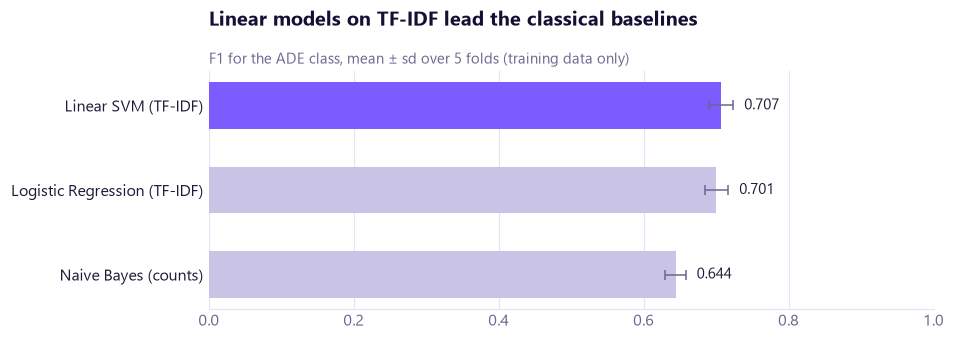

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 2.8))
r = results.sort_values("cv_f1_mean")
ax.barh(r["model"], r["cv_f1_mean"], xerr=r["cv_f1_sd"], color=[VIOLET if i == len(r) - 1 else MUTED for i in range(len(r))],
        height=0.55, error_kw=dict(ecolor=TEXT_2, lw=1, capsize=3))
for y, (v, sd) in enumerate(zip(r["cv_f1_mean"], r["cv_f1_sd"])):
    ax.text(v + sd + 0.015, y, f"{v:.3f}", va="center", fontsize=9.5, color=TEXT)   # label sits past the error bar
ax.set_xlim(0, 1)
ax.set_title("Linear models on TF-IDF lead the classical baselines")
subtitle(ax, "F1 for the ADE class, mean ± sd over 5 folds (training data only)")
viz.save(fig, "07_1_model_comparison")
plt.show()

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · A tokenisation choice you can measure</b>

In notebook 06 we saw that tokenisation choices matter. Here's a measurable example. Our first version kept **hyphenated words whole**, so *"mofetil-**induced** neutropenia"* produced the single rare token `mofetil-induced`, and the model never saw the word **induced**, the strongest ADE cue.
Below: the same models with the two token patterns.

</div>

In [11]:
rows = []
for label, pattern in [("keep hyphenated words whole", r"(?u)\b\w[\w\-]*\b"), ("split on hyphens (used)", r"(?u)\b\w\w+\b")]:
    for name in ["Logistic Regression (TF-IDF)", "Linear SVM (TF-IDF)"]:
        pipe = C.pipelines()[name].set_params(vec__token_pattern=pattern)
        rows.append({"token pattern": label, "model": name,
                     "cv_f1": cross_val_score(pipe, train["text"], train["label"], cv=cv, scoring="f1").mean()})
show(pd.DataFrame(rows), "Same models, different tokenisation", precision=3)

token pattern,model,cv_f1
keep hyphenated words whole,Logistic Regression (TF-IDF),0.657
keep hyphenated words whole,Linear SVM (TF-IDF),0.662
split on hyphens (used),Logistic Regression (TF-IDF),0.701
split on hyphens (used),Linear SVM (TF-IDF),0.707


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

Splitting on hyphens adds **~4.5 F1 points**, more than switching between Naive Bayes, Logistic Regression and SVM. **Look at your tokens before tuning your model.**

</div>

<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- The **majority baseline** scores ~80% accuracy yet finds **zero** side effects. That's why accuracy is the wrong headline metric here.
- **Linear SVM** and **Logistic Regression** (TF-IDF, unigrams + bigrams) are close at ~0.70 F1; Naive Bayes trails.
- The small standard deviations mean the ranking is stable across folds.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 6 · Choosing a decision threshold for safety

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · Precision, recall, and why the threshold is a business decision</b>

- **Precision** = of the sentences we flagged, how many were real ADEs? (false alarms ↓)
- **Recall** = of the real ADEs, how many did we flag? (misses ↓)
- **F1** = harmonic mean of the two. **Macro-F1** averages the per-class F1 equally; **weighted-F1** weights by class size; **micro-F1** pools all decisions (= accuracy for single-label tasks).

In pharmacovigilance, **a missed side effect is worse than a false alarm**: companies must report adverse events, and a human reviews every flag anyway.
So instead of the default 0.5 cut-off, we pick the threshold that reaches **≥ 90% recall on the validation set**, then measure it once on test.

</div>

In [12]:
model = C.pipelines()["Logistic Regression (TF-IDF)"].fit(train["text"], train["label"])   # probabilities + readable weights
val_scores = C.scores(model, val["text"])
thr = C.threshold_for_recall(val["label"], val_scores, target=0.90)

test_scores = C.scores(model, test["text"])
default = C.metrics(test["label"], (test_scores >= 0.5).astype(int), test_scores)
tuned = C.metrics(test["label"], (test_scores >= thr).astype(int), test_scores)
show(pd.DataFrame([{"threshold": "0.50 (default)", **default}, {"threshold": f"{thr:.2f} (≥ 90% recall on val)", **tuned}])
     [["threshold", "accuracy", "precision", "recall", "f1", "macro_f1", "roc_auc", "pr_auc", "tp", "fp", "fn"]],
     "Test-set results: Logistic Regression (TF-IDF), evaluated once", precision=3)

threshold,accuracy,precision,recall,f1,macro_f1,roc_auc,pr_auc,tp,fp,fn
0.50 (default),0.864,0.649,0.730,0.687,0.800,0.916,0.750,468,253,173
0.25 (≥ 90% recall on val),0.768,0.466,0.917,0.618,0.726,0.916,0.750,588,673,53


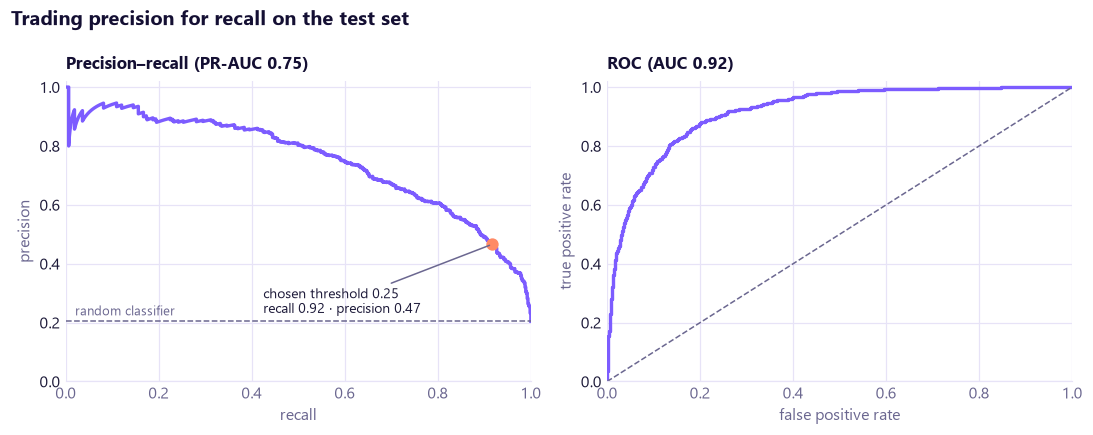

In [13]:
p, rc, t = precision_recall_curve(test["label"], test_scores)
fpr, tpr, _ = roc_curve(test["label"], test_scores)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4))
a1.plot(rc, p, color=VIOLET)
a1.scatter([tuned["recall"]], [tuned["precision"]], color=PEACH, zorder=3, s=50)
a1.annotate(f"chosen threshold {thr:.2f}\nrecall {tuned['recall']:.2f} · precision {tuned['precision']:.2f}",
            (tuned["recall"], tuned["precision"]), xytext=(-150, -45), textcoords="offset points", fontsize=9, color=TEXT,
            arrowprops=dict(arrowstyle="-", color=TEXT_2))
a1.axhline(test["label"].mean(), color=TEXT_2, lw=1, ls="--")
a1.text(0.02, test["label"].mean() + 0.02, "random classifier", fontsize=8.5, color=TEXT_2)
a1.set(xlabel="recall", ylabel="precision", xlim=(0, 1), ylim=(0, 1.02)); a1.grid(axis="y")
a1.set_title(f"Precision–recall (PR-AUC {tuned['pr_auc']:.2f})", fontsize=11, pad=8)
a2.plot(fpr, tpr, color=VIOLET); a2.plot([0, 1], [0, 1], color=TEXT_2, lw=1, ls="--")
a2.set(xlabel="false positive rate", ylabel="true positive rate", xlim=(0, 1), ylim=(0, 1.02)); a2.grid(axis="y")
a2.set_title(f"ROC (AUC {tuned['roc_auc']:.2f})", fontsize=11, pad=8)
fig.suptitle("Trading precision for recall on the test set", x=0.01, ha="left", fontsize=13, fontweight="bold", color=viz.INK)
fig.tight_layout()
viz.save(fig, "07_2_pr_roc")
plt.show()

<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- At the default 0.5 cut-off the model balances precision and recall. Lowering the threshold to reach **~90% recall** catches far more real ADEs, at the cost of more false alarms (lower precision): the deliberate safety-first trade-off.
- **ROC-AUC looks high** partly because there are many easy negatives. **PR-AUC** is the more honest summary when positives are rare: it starts from the 20% "random" line, not 50%.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 7 · Opening the box: which words drive the decision?

</div>

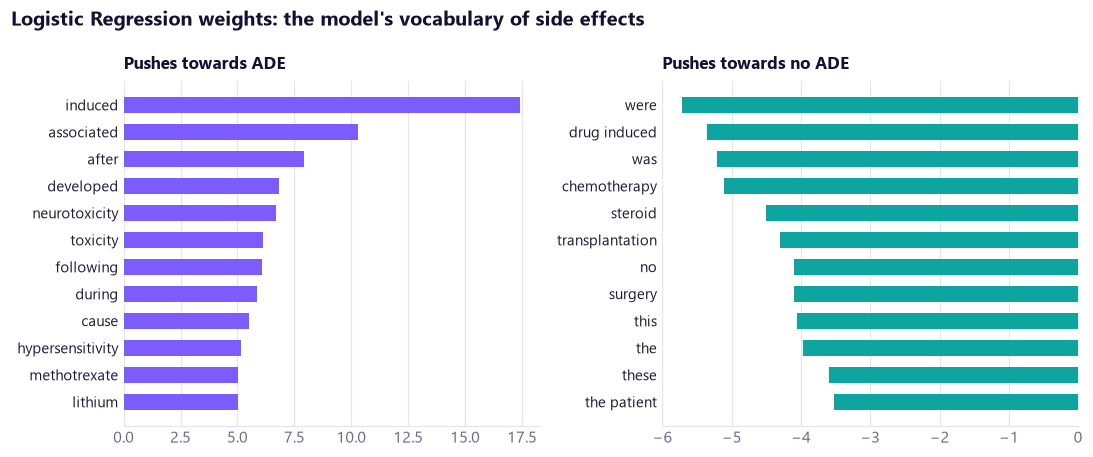

In [14]:
coef = pd.Series(model.named_steps["clf"].coef_[0], index=model.named_steps["vec"].get_feature_names_out())
top_pos, top_neg = coef.nlargest(12)[::-1], coef.nsmallest(12)[::-1]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4.2))
a1.barh(top_pos.index, top_pos.values, color=VIOLET, height=0.6); a1.set_title("Pushes towards ADE", fontsize=11, pad=8)
a2.barh(top_neg.index, top_neg.values, color=TEAL, height=0.6);   a2.set_title("Pushes towards no ADE", fontsize=11, pad=8)
for a in (a1, a2):
    a.tick_params(axis="y", labelsize=9.5)
fig.suptitle("Logistic Regression weights: the model's vocabulary of side effects", x=0.01, ha="left",
             fontsize=13, fontweight="bold", color=viz.INK)
fig.tight_layout()
viz.save(fig, "07_3_top_weights")
plt.show()

<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- **ADE side:** causal and timing words (`induced`, `associated`, `after`, `developed`, `following`, `during`, `cause`), reaction types (`toxicity`, `neurotoxicity`, `hypersensitivity`) and drugs that often appear in case reports (`methotrexate`, `lithium`).
- **No-ADE side:** narrative/study language (`were`, `was`, `this`, `these`), treatment contexts (`chemotherapy`, `steroid`, `transplantation`, `surgery`), and **`no`**: the model learned negation on its own.
- This transparency is a big advantage of linear models: a compliance reviewer can see **why** a sentence was flagged.

</div>

<div style="border-left:6px solid #F43F5E; background:#FFF0F3; color:#881337; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">⚠️ Watch out · Reading coefficients</b>

**`drug induced` has a negative weight, while `induced` has the largest positive one.** They aren't contradictory: whenever "drug induced" appears, "induced" appears too, so the model splits the credit between **correlated features**.
The combined effect is still positive. Never interpret one coefficient in isolation when features overlap (n-grams always do).

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · Error analysis</b>

Metrics tell you **how much** a model fails; reading errors tells you **why**. Typical causes: missing context, rare wording, negation, or **label noise** (the gold label itself is debatable).

</div>

In [15]:
test_view = test.assign(score=test_scores, pred=(test_scores >= thr).astype(int))
fn = test_view[(test_view["label"] == 1) & (test_view["pred"] == 0)].nsmallest(4, "score")
fp = test_view[(test_view["label"] == 0) & (test_view["pred"] == 1)].nlargest(4, "score")
display(show(fn[["score", "text"]], "Missed ADEs (false negatives): lowest scores", precision=3))
show(fp[["score", "text"]], "False alarms (false positives): highest scores", precision=3)

score,text
0.037,Loperamide poisoning in the dog.
0.055,"Further studies are necessary to evaluate whether the study of HLA antigens may be a very useful tool to detect the patients with a predisposition to develop autoimmune thyroiditis, in order to make a early diagnosis of thyroid disorders during the IFN-alpha treatment."
0.058,The patient developed occipital infarcts and was found to have extremely elevated levels of PPA in his blood and dialysis fluid.
0.064,"While doxorubicin was administered, the patient presented thoracic pain and breathing distress due to superior vena cava perforation by the central catheter and subsequent extravasation of the drug into the mediastinum."


score,text
0.998,Pharmacokinetically induced benzodiazepine withdrawal.
0.993,Non-lithium-induced renal failure with secondary lithium toxicity: case reports.
0.989,CONCLUSIONS: Exposure to vanadium can cause a metal fume fever-like syndrome associated with neutrophilic alveolitis.
0.972,Ferrous sulfate-induced increase in requirement for thyroxine in a patient with primary hypothyroidism.


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

Read the actual sentences above: three different kinds of error show up.
- **No cue words:** some true ADEs describe the event without "induced / caused / after" (e.g. a *poisoning* report), so BoW has nothing to latch onto. Understanding meaning needs context, which is what transformers add.
- **Negation and causality the model cannot read:** "**Non**-lithium-induced renal failure" contains the cue word *induced* but negated by *non-*; other false alarms mention a drug and a condition without a causal link.
- **Label noise:** some "errors" are arguably correct predictions. Look for false alarms that clearly describe a side effect, and "missed ADEs" that don't mention one. Even expert-labelled corpora have a noise floor, so no model can reach 100%.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 8 · Trying it on GLP-1 research text (domain shift)

</div>

In [16]:
corpus = P.build_corpus()
sentences = pd.Series([s for t in corpus.loc[corpus["source"] == "pubmed", "text"].sample(800, random_state=3)
                       for s in __import__("nltk").sent_tokenize(t)])
flag = pd.DataFrame({"sentence": sentences, "score": C.scores(model, sentences)})
show(flag.nlargest(6, "score")[["score", "sentence"]], "GLP-1 abstract sentences the model scores as most ADE-like", precision=3)
print(f"Flagged at the chosen threshold: {(flag['score'] >= thr).mean():.0%} of {len(flag):,} sentences")

Flagged at the chosen threshold: 15% of 8,738 sentences


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- The top-scoring sentences use typical ADE language (*"associated with"*, *"induced"*, adverse-event wording), so the model **transfers to some degree**.
- But many flagged sentences are **trial statistics** ("adverse events were mostly gastrointestinal…"), not reports of a specific patient's side effect: the same words in a different kind of text.

</div>

<div style="border-left:6px solid #F43F5E; background:#FFF0F3; color:#881337; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">⚠️ Watch out</b>

**Domain shift:** the model learned from 1990s–2000s case reports, not GLP-1 trials or rep visit notes. Before using it on visit notes we must **evaluate on labelled visit notes** (notebook 09 creates them) and expect to fine-tune.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 9 · Save the baseline and summarise

</div>

In [17]:
C.save_metrics("nb07_tfidf_baselines", {
    "task": "ADE sentence classification (ADE Corpus v2, deduplicated)",
    "split": {"train": len(train), "val": len(val), "test": len(test), "seed": C.SEED},
    "cv_f1_train": results.set_index("model")[["cv_f1_mean", "cv_f1_sd"]].round(4).to_dict("index"),
    "test_logreg_default_threshold": default,
    "test_logreg_recall90_threshold": {**tuned, "threshold": round(thr, 4)},
    "leakage_check_f1": {"with_duplicates": round(leaky, 4), "deduplicated": round(clean_, 4)},
})
print("saved → reports/evaluation/nb07_tfidf_baselines.json")

saved → reports/evaluation/nb07_tfidf_baselines.json


<div style="border-left:6px solid #F43F5E; background:#FFF0F3; color:#881337; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">⚠️ Limitations</b>

1. BoW ignores word order and meaning: synonyms (*vomiting / emesis*) are unrelated features.
2. Trained on case-report English; visit notes and trial abstracts differ (domain shift).
3. The 90% recall target is a policy choice, made with stakeholders, not a technical constant.
4. Labels contain some noise; the "ceiling" on this test set is below 100%.

</div>

<div style="border-left:6px solid #10B981; background:#EAFBF1; color:#065F46; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">🎯 Key takeaways</b>

**Done:** an honest, explainable ADE baseline (deduplicated data, stratified splits, CV model choice, recall-first threshold, one test evaluation), saved for comparison.
**Next:** notebook 08 (word embeddings + topic modelling), then transformers (notebooks 10–12), which must beat **this** F1 / PR-AUC.

**Check your understanding**
- *What is TF-IDF?* Term frequency × inverse document frequency: rewards words frequent in a document but rare across the corpus; rows L2-normalised.
- *Why is accuracy misleading here?* 80% accuracy by always saying "no ADE"; use precision, recall, F1, PR-AUC.
- *Macro vs weighted vs micro F1?* Equal weight per class vs weighted by class size vs pooled decisions.
- *How do you pick a threshold?* On validation, from business cost: recall ≥ 90% because a missed side effect costs more than a false alarm.
- *What is data leakage, and where did you find it?* 2,620 duplicate sentences could sit in train and test; deduplicate before splitting.
- *ROC-AUC or PR-AUC with imbalance?* PR-AUC: its baseline is the positive rate, so it isn't flattered by easy negatives.
- *Why start with linear models?* Fast, strong baselines with readable weights, the bar any deep model must clearly beat.
- *Biggest single improvement?* Splitting hyphenated tokens (+4.5 F1), a preprocessing fix, not a model change.

</div>